In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [5]:
import pandas as pd

geo = pd.read_csv(
    "../data/coordonnees_pluviometres_flowbru.csv"
)

print("Nombre de pluviomètres :", len(geo))

display(geo[[
    "nom",
    "latitude",
    "longitude",
    "bassin_versant"
]])

Nombre de pluviomètres : 16


,nom,latitude,longitude,bassin_versant
0,Avant-Port,50.882602,4.386583,Senne
1,Ganshoren,50.881422,4.301498,Molenbeek
2,Roodebeek,50.848352,4.430479,Woluwe
3,Hippocrate,50.855499,4.446083,Woluwe
4,Écluse Anderlecht,50.819198,4.301812,Senne
5,Paelincks,50.770345,4.387502,Ukkelbeek
6,Kinsendael,50.786960,4.354279,Ukkelbeek
7,Semence,50.852594,4.299759,Broek-Neerpede / Vogelzangbeek
8,Dépôt Communal,50.812555,4.400667,Woluwe
9,Voets,50.806299,4.452897,Woluwe


Afficher les 16 pluviomètres sur une carte simple

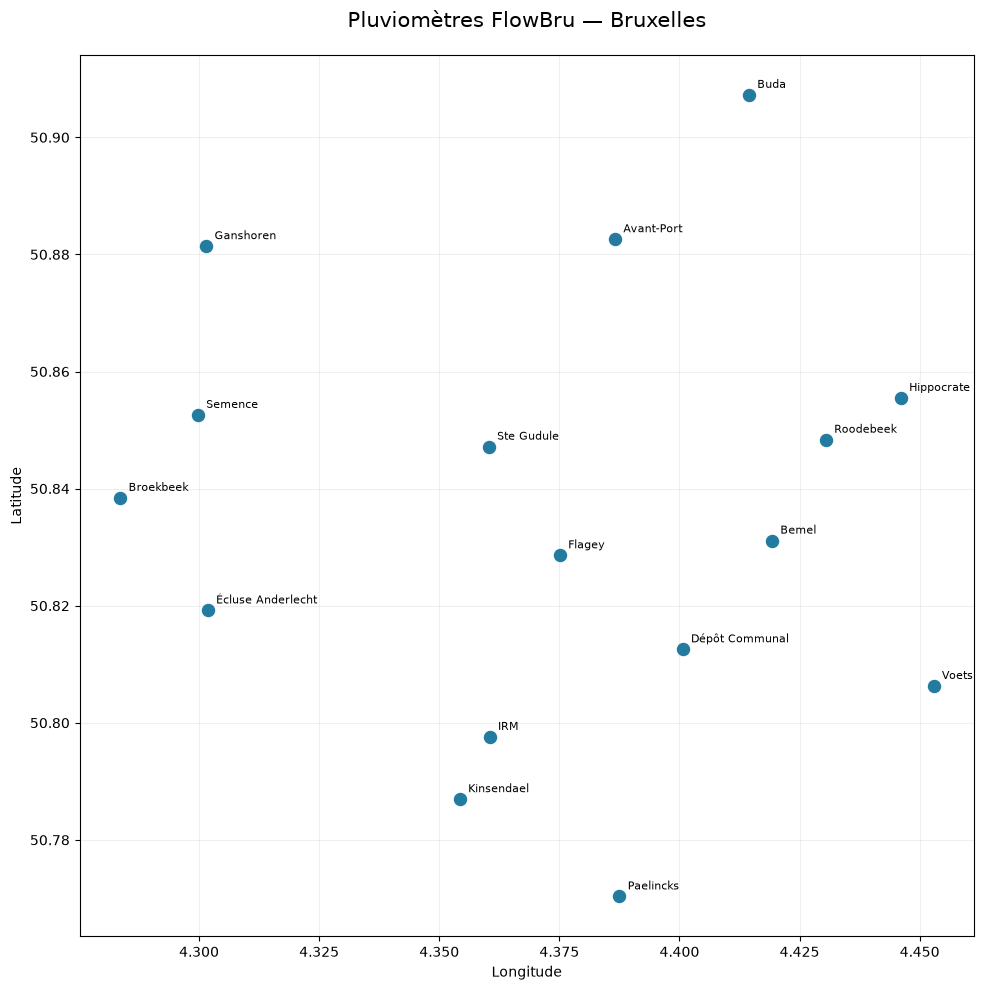

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))

# Placer les stations selon leurs coordonnées GPS
ax.scatter(
    geo["longitude"],
    geo["latitude"],
    s=75,
    color="#247BA0",
    zorder=3
)

# Ajouter le nom de chaque station
for _, station in geo.iterrows():
    ax.annotate(
        station["nom"],
        (station["longitude"], station["latitude"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Pluviomètres FlowBru — Bruxelles",
    fontsize=15,
    pad=20
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(alpha=0.2)
ax.set_aspect(
    1 / np.cos(np.deg2rad(geo["latitude"].mean()))
    if False else "auto"
)

plt.tight_layout()
plt.show()

Vérifier la correspondance avec les mesures de pluie

In [10]:
mesures = pd.read_csv(
    "../data/24_juillet_2025_donnees_preparees.csv"
)

colonnes_pluie = mesures.columns[1:17].tolist()

# Comparer les noms de stations aux colonnes du CSV
for _, station in geo.iterrows():
    colonne = station["colonne_pluie_csv"]

    if colonne in colonnes_pluie:
        print("OK :", station["nom"])
    else:
        print("À vérifier :", station["nom"], "→", colonne)

OK : Avant-Port
OK : Ganshoren
OK : Roodebeek
OK : Hippocrate
À vérifier : Écluse Anderlecht → pluv.écluse;anderlecht
OK : Paelincks
OK : Kinsendael
OK : Semence
OK : Dépôt Communal
OK : Voets
À vérifier : IRM → pluv.IRM
OK : Flagey
OK : Ste Gudule
OK : Bemel
OK : Broekbeek
OK : Buda


Correction de 2 noms des pluviometre pour garder la correspondance avec les fichers CSV

In [11]:
# Corriger les noms pour qu'ils correspondent au CSV des mesures
geo.loc[
    geo["nom"] == "Écluse Anderlecht",
    "colonne_pluie_csv"
] = "pluv.écluse;anderlecht"

# Vérifier le nom exact de la colonne IRM
print([col for col in colonnes_pluie if "irm" in col.lower()])


['pluv.irm']


In [13]:
print("IRM existe :", "pluv.IRM" in mesures.columns)

print(
    "Écluse Anderlecht existe :",
    "pluv.écluse;anderlecht" in mesures.columns
)

IRM existe : False
Écluse Anderlecht existe : False


In [14]:
for i, colonne in enumerate(mesures.columns):
    print(i, repr(colonne))

0 'Date/heure locale (UTC+2)'
1 'Pluv_Buda'
2 'pluv.Avant-port'
3 'pluv.Genshoren'
4 'pluv.bernel'
5 'pluv.broebeek'
6 'pluv.depot.commun'
7 'pluv.écluse;anderlecht'
8 'pluv.flagey'
9 'pluv.hippocrate'
10 'pluv.irm'
11 'pluv.kinsendael'
12 'pluv.paelinckx'
13 'pluv.roodebeek'
14 'pluv.semence'
15 'pluv.ste.gudule'
16 'pluv.voets'
17 'Q01'
18 'Q02'
19 'Q03'
20 'Q04'


In [17]:
# Recharger le fichier de mesures
mesures = pd.read_csv(
    "../data/24_juillet_2025_donnees_preparees.csv"
)

# Corriger les deux correspondances
geo.loc[
    geo["nom"] == "IRM",
    "colonne_pluie_csv"
] = "pluv.irm"

geo.loc[
    geo["nom"] == "Écluse Anderlecht",
    "colonne_pluie_csv"
] = "pluv.écluse;anderlecht"

In [20]:
for _, station in geo.iterrows():
    colonne = station["colonne_pluie_csv"]

    if colonne in mesures.columns:
        print("OK :", station["nom"], "=", colonne)
    else:
        print("À vérifier :", station["nom"], "=", colonne)

OK : Avant-Port = pluv.Avant-port
OK : Ganshoren = pluv.Genshoren
OK : Roodebeek = pluv.roodebeek
OK : Hippocrate = pluv.hippocrate
OK : Écluse Anderlecht = pluv.écluse;anderlecht
OK : Paelincks = pluv.paelinckx
OK : Kinsendael = pluv.kinsendael
OK : Semence = pluv.semence
OK : Dépôt Communal = pluv.depot.commun
OK : Voets = pluv.voets
OK : IRM = pluv.irm
OK : Flagey = pluv.flagey
OK : Ste Gudule = pluv.ste.gudule
OK : Bemel = pluv.bernel
OK : Broekbeek = pluv.broebeek
OK : Buda = Pluv_Buda


Pour corriger le fait que certains noms utilisent des unicode different et ne sont pas reconnus dans le CVS/dossier données

In [21]:
import unicodedata

# Uniformiser les accents dans les deux fichiers
mesures.columns = [
    unicodedata.normalize("NFC", col)
    for col in mesures.columns
]

geo["colonne_pluie_csv"] = geo["colonne_pluie_csv"].apply(
    lambda nom: unicodedata.normalize("NFC", nom)
)